# Assignment 4: Simulate response to weather

**Author:** Lino Kaiser.

We use the validated building and circuit from notebooks [1](01_model.ipynb) and [2](02_steady_state.ipynb), with the 15 s time step selected in [3](03_simulate_step_response.ipynb). We simulate winter and summer weather, solar radiation and internal gains, then compare heating controllers and window shading. Shared weather preparation and explicit Euler integration are in [simulation.py](simulation.py).


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from scipy.optimize import minimize

import dm4bem
import thermal_model as model
import simulation

boundary = model.boundary
zone_labels = ["Project room", "Office"]
colors = ["#1764ab", "#d97721"]
state_nodes = np.flatnonzero(model.capacities)
air_states = np.flatnonzero(np.isin(state_nodes, model.air_nodes))
kp = 500.0  # W/K per room, as in the steady-state heating case
plt.rcParams.update({
    "figure.figsize": (11, 5), "font.size": 10,
    "axes.grid": True, "grid.alpha": 0.2,
    "axes.spines.top": False, "axes.spines.right": False,
})
dt = 15.0  # s, selected and checked in notebook 3


## 1. Zurich Airport weather data

We use [CHE_ZH_Zurich.AP.066700_TMYx.2009-2023.epw](weather_data/CHE_ZH_Zurich.AP.066700_TMYx.2009-2023.epw), downloaded from [Climate.OneBuilding](https://climate.onebuilding.org/WMO_Region_6_Europe/CHE_Switzerland/ZH_Zurich/CHE_ZH_Zurich.AP.066700_TMYx.2009-2023.zip). It is a typical meteorological year assembled from the 2009–2023 period.

The supplied EPW reader is reused unchanged. We map the file to the non-leap year 2023 for a consistent weekday schedule. The EPW index marks the start of each hourly interval in fixed UTC+1. Radiation in Wh/m² over one hour is numerically equal to mean W/m² for that hour. Occupancy uses Zurich civil time, including daylight saving, without shifting the weather itself.

In [2]:
filename = Path("weather_data/CHE_ZH_Zurich.AP.066700_TMYx.2009-2023.epw")
data, meta = dm4bem.read_epw(filename, coerce_year=2023)
weather = data[["temp_air", "dir_n_rad", "dif_h_rad", "ghi"]].copy()
assert len(weather) == 8760 and weather.index.is_unique
assert weather.index.is_monotonic_increasing
assert (weather.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all()
assert np.isfinite(weather.to_numpy()).all()
assert weather["temp_air"].between(-70, 70).all()
assert weather[["dir_n_rad", "dif_h_rad", "ghi"]].ge(0).all().all()
assert weather[["dir_n_rad", "dif_h_rad", "ghi"]].lt(9999).all().all()
assert meta["WMO_code"] == "066700"
display(pd.Series({key: meta[key] for key in
                   ["city", "WMO_code", "latitude", "longitude", "altitude", "TZ"]}))
display(weather.describe().loc[["min", "mean", "max"]].round(2))

city         Zurich.AP
WMO_code        066700
latitude       47.4797
longitude       8.5358
altitude         427.4
TZ                 1.0
dtype: object

,temp_air,dir_n_rad,dif_h_rad,ghi
min,-9.80,0.00,0.00,0.00
mean,10.49,164.47,54.62,145.38
max,32.30,927.00,385.00,900.00


## 2. Solar radiation and occupancy inputs

The supplied solar helper calculates direct and diffuse radiation on the four facades. We evaluate its approximate solar geometry at the interval midpoint, with longitude and equation-of-time corrections. The flat roof receives EPW global horizontal radiation directly.

Opaque surfaces use the sol-air temperature $T_\mathrm{sa}=T_o+\alpha R_\mathrm{outside}I$, retaining the outside film resistance already in the circuit. Each room's wall irradiance is weighted by opaque facade area. Window gains are $Q_\mathrm{solar}=S_\mathrm{window}\,0.8\,0.6\,I$ and enter the corresponding floor storage node, a simple lumped assumption for indoor solar absorption. Sun patches and separate radiant distributions are omitted. No additional window absorption is added because the g-value already represents total solar gain. Solar absorption by the exterior door and window frame is neglected.

Internal gains remain 680 W / 340 W during Monday–Friday 08:00–18:00. Ventilation switches between 1 and 0.3 ACH; ground stays at 10 °C. The heated comparison uses $Q_h=\max[0,500(T_\mathrm{set}-T_\mathrm{air})]$ in each room, with 21/16 °C setpoints, no cooling and no prescribed maximum heating capacity.

In [3]:
hourly, solar_table = simulation.solar_inputs(weather, meta)
occupied_gains = simulation.occupied_gains
display(solar_table.fillna(0).rename(columns={
    "north": "North wall [m²]", "south": "South wall [m²]",
    "east": "East wall [m²]", "west": "West wall [m²]",
}).round(2))
print("Occupied internal gains [W]:", occupied_gains)

,North wall [m²],South wall [m²],West wall [m²],Annual window gain [kWh],East wall [m²]
Zone,,,,,
project_room,15.9,12.0,18.0,2990.61,0.0
office,7.2,9.0,0.0,338.11,18.0


Occupied internal gains [W]: [680. 340.]


## 3. Weather simulation

We compare weather alone, weather + solar, weather + solar + internal gains, and full inputs with heating. The first three are free-running, making the added heat sources visible.

Displayed periods are 16–23 January and 17–24 July on the synthetic 2023 calendar. All states start at 20 °C **60 days before** each week. January's warm-up wraps the same typical year's November–December weather to the preceding year. Solar power is held constant within each EPW hour to preserve hourly energy; outdoor temperature is interpolated linearly. Occupancy and setpoints switch at their scheduled times.
At each time step, $u(t)$ contains the selected temperature sources followed by heat-flow sources at nodes 0, 5, 7 and 12. These include internal gains, window gains and, when active, heating; the table below shows three winter examples.


In [4]:
# Reuse the shared weather preparation and Euler simulation.
def sampled_weather(start, stop, step, warmup_days=60):
    return simulation.sampled_weather(hourly, start, stop, step, warmup_days)


def simulate_weather(sample, step, solar=True, internal=True, heating=False, initial=20.0):
    return simulation.simulate_weather(
        sample, step, solar, internal, heating, initial, kp=kp)

periods = {"Winter": ("2023-01-16", "2023-01-23"),
           "Summer": ("2023-07-17", "2023-07-24")}
scenarios = {
    "Weather only": dict(solar=False, internal=False),
    "+ Solar": dict(solar=True, internal=False),
    "+ Internal gains": dict(solar=True, internal=True),
    "With heating": dict(solar=True, internal=True, heating=True),
}
weather_results = {}
week_inputs = {}
for season, (start, stop) in periods.items():
    sample = sampled_weather(start, stop, dt)
    start_stamp = pd.Timestamp(start, tz=weather.index.tz)
    week_inputs[season] = sample.loc[start_stamp:]
    weather_results[season] = {}
    for name, options in scenarios.items():
        result = simulate_weather(sample, dt, **options)
        weather_results[season][name] = result.loc[start_stamp:]
    print(f"{season}: four scenarios simulated, with 60 days of warm-up.")

# Additional nonnegative heat sources cannot lower either room temperature.
for season, results in weather_results.items():
    names = list(scenarios)
    for before, after in zip(names[:-1], names[1:]):
        columns = ["Project [°C]", "Office [°C]"]
        assert (results[after][columns].to_numpy()
                >= results[before][columns].to_numpy() - 1e-8).all()
# Show complete input vectors for three times in the heated winter run.
preview_times = pd.date_range("2023-01-16", periods=3, freq="6h", tz=weather.index.tz)
preview = week_inputs["Winter"].loc[preview_times]
u_preview = simulation.input_values(preview)
for j, node in enumerate(model.air_nodes):
    col = len(simulation.source_branches) + np.flatnonzero(simulation.flow_nodes == node)[0]
    u_preview[:, col] += weather_results["Winter"]["With heating"].loc[
        preview_times, ["Project heating [W]", "Office heating [W]"][j]
    ].to_numpy()
display(pd.DataFrame(u_preview.T, index=simulation.input_names, columns=preview_times).round(2))


Winter: four scenarios simulated, with 60 days of warm-up.
Summer: four scenarios simulated, with 60 days of warm-up.


,2023-01-16 00:00:00+01:00,2023-01-16 06:00:00+01:00,2023-01-16 12:00:00+01:00
b_T[0] [°C]: outdoor,3.30,1.10,10.04
b_T[4] [°C]: outdoor,3.30,1.10,13.92
b_T[8] [°C]: ground,10.00,10.00,10.00
b_T[12] [°C]: outdoor,3.30,1.10,5.50
b_T[13] [°C]: outdoor,3.30,1.10,5.50
b_T[14] [°C]: outdoor,3.30,1.10,5.50
b_T[15] [°C]: setpoint,16.00,16.00,21.00
b_T[16] [°C]: outdoor,3.30,1.10,10.20
b_T[20] [°C]: outdoor,3.30,1.10,13.92
b_T[24] [°C]: ground,10.00,10.00,10.00


## 4. Numerical checks

We repeat the heated simulation, including warm-up, at half the selected time step and compare temperatures at matching timestamps. We also repeat the winter free-running case from an initial 0 °C instead of 20 °C to check that the displayed week is insensitive to initialization.

In [5]:
weather_checks = []
for season, (start, stop) in periods.items():
    finer = sampled_weather(start, stop, dt / 2)
    fine_result = simulate_weather(finer, dt / 2, heating=True)
    coarse = weather_results[season]["With heating"]
    columns = ["Project [°C]", "Office [°C]"]
    error = np.max(np.abs(fine_result.loc[coarse.index, columns].to_numpy()
                          - coarse[columns].to_numpy()))
    assert error < 0.1, (season, error)
    weather_checks.append({"Period": season, "15 s / 7.5 s max error [K]": error})
start, stop = periods["Winter"]
sample = sampled_weather(start, stop, dt)
cold_start = simulate_weather(sample, dt, initial=0.0)
reference = weather_results["Winter"]["+ Internal gains"]
warmup_error = np.max(np.abs(cold_start.loc[reference.index, columns].to_numpy()
                              - reference[columns].to_numpy()))
assert warmup_error < 0.1, warmup_error
display(pd.DataFrame(weather_checks).set_index("Period").round(4))
print(f"Initial 0 / 20 °C: max displayed-week difference {warmup_error:.4f} K.")
print("All weather checks passed.")

,15 s / 7.5 s max error [K]
Period,
Winter,0.0638
Summer,0.0087


Initial 0 / 20 °C: max displayed-week difference 0.0138 K.
All weather checks passed.


## 5. Weather inputs and room-temperature results

Input plots show outdoor temperature, facade/roof irradiance and internal heat. Temperature plots add these inputs one at a time. Heating is a separate comparison with full inputs; its power is always nonnegative.

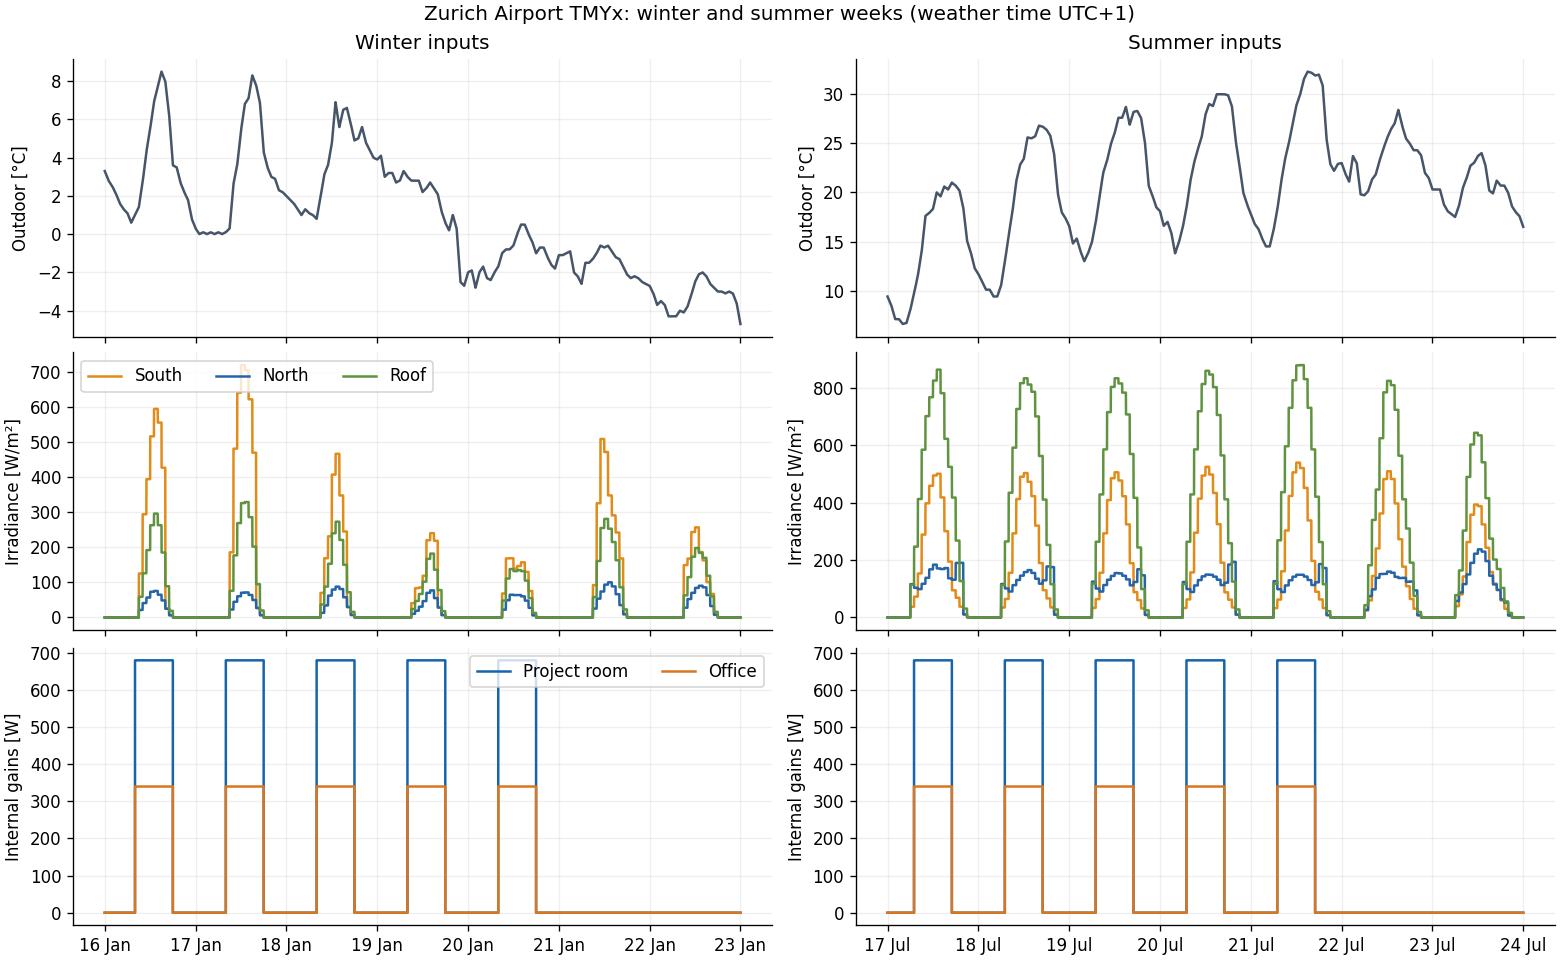

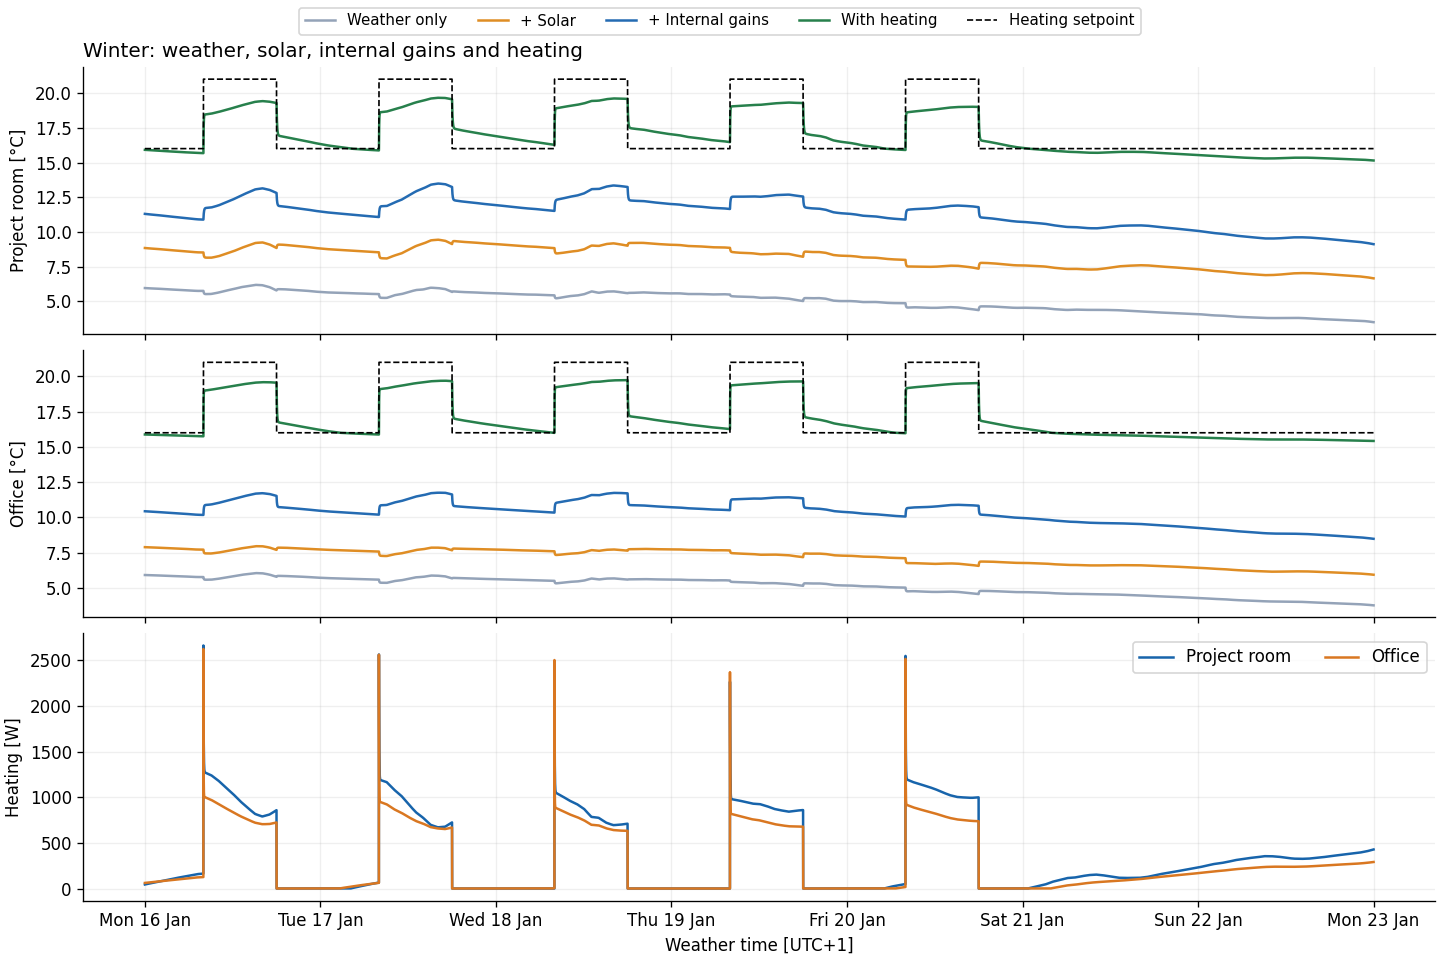

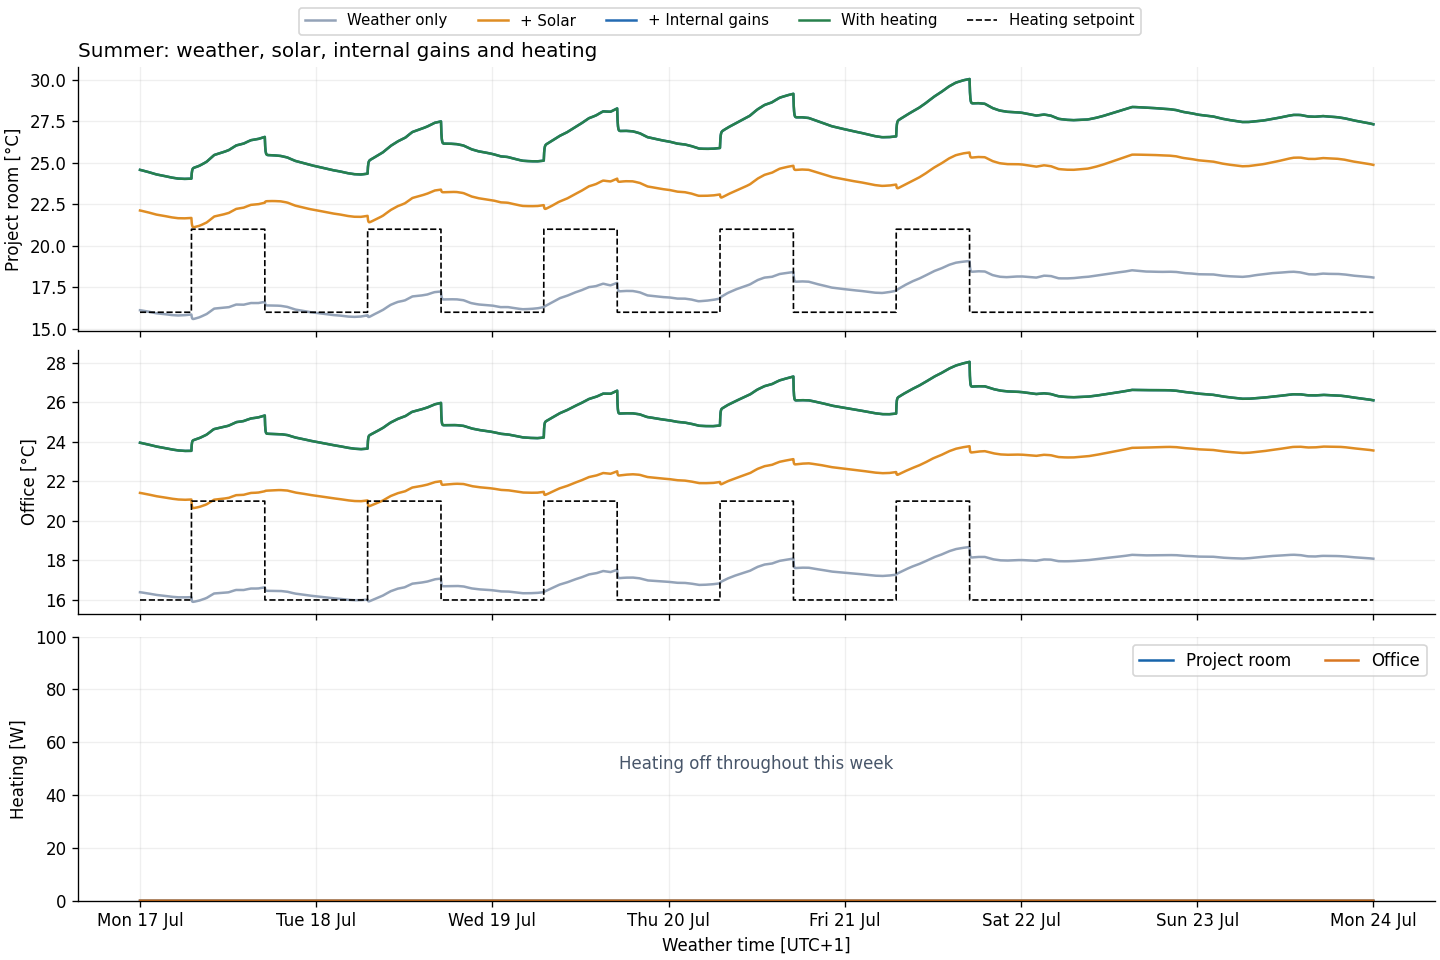

In [6]:
fig, axes = plt.subplots(3, 2, figsize=(13, 8), sharex="col", constrained_layout=True)
for col, season in enumerate(periods):
    sample = week_inputs[season]
    axes[0, col].plot(sample.index, sample["temp_air"], color="#475569")
    axes[0, col].set(title=season + " inputs", ylabel="Outdoor [°C]")
    for orientation, color in [("south", "#e18b18"), ("north", "#2564a8"), ("roof", "#60933f")]:
        axes[1, col].plot(sample.index, sample[orientation], color=color, label=orientation.title())
    axes[1, col].set(ylabel="Irradiance [W/m²]")
    for j, label in enumerate(zone_labels):
        axes[2, col].step(sample.index, occupied_gains[j] * sample["occupied"], where="post",
                          label=label, color=colors[j])
    axes[2, col].set(ylabel="Internal gains [W]")
    axes[2, col].xaxis.set_major_formatter(mdates.DateFormatter("%d %b", tz=weather.index.tz))
axes[1, 0].legend(ncol=3, loc="upper left")
axes[2, 0].legend(ncol=2)
fig.suptitle("Zurich Airport TMYx: winter and summer weeks (weather time UTC+1)")
plt.show()

scenario_colors = {"Weather only": "#94a3b8", "+ Solar": "#df8d24",
                   "+ Internal gains": "#246bb2", "With heating": "#27804c"}
for season in periods:
    fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, constrained_layout=True)
    for name, result in weather_results[season].items():
        for j, column in enumerate(["Project [°C]", "Office [°C]"]):
            axes[j].plot(result.index, result[column], color=scenario_colors[name], label=name)
    heated = weather_results[season]["With heating"]
    for j, label in enumerate(zone_labels):
        axes[j].plot(heated.index, heated["Setpoint [°C]"], color="black", linestyle="--",
                     linewidth=1, label="Heating setpoint")
        axes[j].set(ylabel=label + " [°C]")
    for j, column in enumerate(["Project heating [W]", "Office heating [W]"]):
        axes[2].plot(heated.index, heated[column], color=colors[j], label=zone_labels[j])
    axes[2].set(ylabel="Heating [W]", xlabel="Weather time [UTC+1]")
    axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b", tz=weather.index.tz))
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside upper center", ncol=5, fontsize=9)
    if heated[["Project heating [W]", "Office heating [W]"]].to_numpy().max() < 1e-9:
        axes[2].set_ylim(0, 100)
        axes[2].text(0.5, 0.5, "Heating off throughout this week",
                     transform=axes[2].transAxes, ha="center", color="#475569")
    axes[2].legend(ncol=2)
    axes[0].set_title(season + ": weather, solar, internal gains and heating", loc="left")
    plt.show()

In [7]:
summary_rows = []
for season, results in weather_results.items():
    for name, result in results.items():
        intervals = result.iloc[:-1]  # Last row is an endpoint, not another interval.
        summary_rows.append({
            "Period": season, "Scenario": name,
            "Project min [°C]": intervals["Project [°C]"].min(),
            "Project max [°C]": intervals["Project [°C]"].max(),
            "Office min [°C]": intervals["Office [°C]"].min(),
            "Office max [°C]": intervals["Office [°C]"].max(),
            "Heating [kWh]": intervals[["Project heating [W]", "Office heating [W]"]].to_numpy().sum() * dt / 3.6e6,
        })
weather_summary = pd.DataFrame(summary_rows).set_index(["Period", "Scenario"])
display(weather_summary.round(2))

Project min [°C]  ...  Heating [kWh]
Period Scenario                            ...               
Winter Weather only                  3.51  ...            0.0
       + Solar                       6.66  ...            0.0
       + Internal gains              9.12  ...            0.0
       With heating                 15.14  ...          106.3
Summer Weather only                 15.59  ...            0.0
       + Solar                      21.12  ...            0.0
       + Internal gains             24.03  ...            0.0
       With heating                 24.03  ...            0.0

[8 rows x 5 columns]

## 6. Interpretation and limits

- The selected 15 s step is well below the 158.32 s stability bound. Its largest step-response error against exact integration is 0.023 K; halving the weather step changes temperatures by at most 0.064 K in winter and 0.009 K in summer.
- Solar and internal gains raise free-running temperatures relative to weather alone. Larger south-facing glazing gives the project room stronger direct solar gains than the office's north-facing window.
- Thermal storage delays the response and keeps temperatures elevated after sunlight or occupancy gains disappear. Heat exchange between the rooms couples their responses.
- With full gains but no heating, the winter project room ranges from 9.1 to 13.5 °C and the office from 8.5 to 11.7 °C. The heated case uses 106.3 kWh for this week. Winter heating rises at the morning setpoint increase and falls when solar and internal gains contribute. Proportional control has a finite tracking error; 21 °C is a target, not an imposed room temperature. Both rooms peak at about 19.7 °C in the heated winter run.
- With solar and internal gains, summer peaks reach 30.0 °C in the project room and 28.0 °C in the office. The heated and unheated full-input curves overlap because heating stays off during this week. Heating cannot prevent summer overheating. This baseline has no cooling, external shading or extra night ventilation.
- These are simplified-model predictions for two typical-year weeks. Airport weather is used as a proxy for Winterthur. Surface films, indoor solar-gain distribution and approximate solar geometry remain modelling assumptions.


## 7. Comparison setup

We use the same January and July weeks, occupancy, solar gains and 15 s simulation step as the weather simulations above. Insulation, ventilation and the thermal circuit stay unchanged. Each study starts from one common state obtained with 60 days of proportional-control warm-up; each alternative starts from that same state. Shading is deployed at the start of the summer comparison.

For this controller comparison, heating power is limited to **2000 W in the project room and 1000 W in the office**, for every controller. These are assumed equipment limits, approximately twice the occupied heating demand calculated in notebook 2. The weather baseline above had no power cap. The occupied setpoint is 21 °C and the unoccupied setpoint 16 °C. Nothing can provide cooling.

We assess occupied comfort using an assumed 20.5–21.5 °C band in winter and count occupied hours above an assumed 26 °C threshold in summer. These are our comparison criteria. Weather timestamps remain UTC+1 while occupancy follows Zurich civil time.

In [8]:
DT = dt
CONTROL_SECONDS = 15 * 60
HORIZON_HOURS = 6
CONTROL_STEPS = int(CONTROL_SECONDS / DT)
HORIZON_STEPS = int(HORIZON_HOURS * 3600 / CONTROL_SECONDS)
POWER_LIMIT = np.array([2000.0, 1000.0])  # W: project room, office
HALF_BAND = 0.5                         # K
TRACKING_WEIGHT = 50.0
BAND_WEIGHT = 200.0
zone_labels = ["Project room", "Office"]
air_states = simulation.air_states
capacities = model.capacities[simulation.state_nodes]
air_capacity = model.capacities[model.air_nodes]

# Check the explicit Euler limit with both ventilation rates and full P feedback.
limits = []
for ach in [model.boundary["unoccupied_ACH"], model.boundary["occupied_ACH"]]:
    eigenvalues = np.linalg.eigvals(model.state_space(ach=ach, kp=500.0)[0]).real
    limits.append(np.min(-2 / eigenvalues))
assert DT < min(limits)
print(f"Simulation step: {DT:g} s; P-controller stability limit: {min(limits):.2f} s.")
print(f"MPC: {HORIZON_HOURS} h horizon, {CONTROL_SECONDS / 60:g} min between decisions.")

Simulation step: 15 s; P-controller stability limit: 158.32 s.
MPC: 6 h horizon, 15 min between decisions.


In [9]:
samples = {}
initial_states = {}
for season, (start, stop) in periods.items():
    # The additional six hours provide a complete forecast at the end of the week.
    forecast_stop = pd.Timestamp(stop) + pd.Timedelta(hours=HORIZON_HOURS)
    extended = simulation.sampled_weather(hourly, start, forecast_stop, DT)
    start_time = pd.Timestamp(start, tz=hourly.index.tz)
    warmup = extended.loc[:start_time]
    _, initial_states[season] = simulation.simulate_weather(
        warmup, DT, heating=True, max_power=POWER_LIMIT, return_state=True)
    samples[season] = extended.loc[start_time:]

print("Both studies start from their common 60-day warm-up state.")
display(pd.DataFrame(initial_states, index=[
    model.node_names[j] for j in simulation.state_nodes
]).rename_axis("Initial state [°C]").round(2))


Both studies start from their common 60-day warm-up state.


,Winter,Summer
Initial state [°C],,
Project air,15.91,24.57
Project wall mass,15.90,24.71
Project roof mass,16.10,25.07
Project floor mass,17.65,26.71
Office air,15.88,23.95
Office wall mass,15.85,24.06
Office roof mass,16.01,24.43
Office floor mass,16.16,24.34
Shared partition,16.08,24.58


## 8. Winter heating controllers

**Proportional control:** $Q_h=\mathrm{clip}[500(T_\mathrm{set}-T_\mathrm{air}),0,Q_\mathrm{max}]$. This is the existing controller with the common power limits added.

**Dead-band thermostat:** heating switches fully on below $T_\mathrm{set}-0.5$ °C and off above $T_\mathrm{set}+0.5$ °C. Between these limits it keeps its previous on/off state. This allows a small temperature swing and avoids switching at every small movement around the target. The heater starts off and the thresholds are checked immediately.

**Model predictive control (MPC):** every 15 minutes, predict both rooms over the next six hours and choose heating powers between zero and the equipment limits. Apply only the first 15-minute command, then plan again from the updated state. We assume the complete storage state and future weather/occupancy are known. This is an ideal forecast comparison.

The MPC minimizes heating energy plus penalties for occupied temperature error and excursions outside the allowed band. The tracking and band weights are chosen as 50 and 200 since they strongly favour comfort and are not energy prices. During unoccupied hours, the lower bound is 15.5 °C and the upper bound remains 21.5 °C so that preheating is allowed. Temperature limits are soft penalties while heating-power limits are hard bounds.

The prediction below combines consecutive 15 s Euler steps into 15-minute blocks, including the changing weather inputs. The building itself is still integrated at 15 s. Comfort penalties are evaluated at the block endpoints and reported comfort uses the full 15 s results.

In [10]:
def prediction_blocks(sample, Ad, forcing):
    """Combine the fine Euler steps without changing the prediction dynamics."""
    identity = np.eye(len(capacities))
    heat_input = np.zeros((len(capacities), 2))
    heat_input[air_states, np.arange(2)] = DT * 1000 / air_capacity  # K per kW
    transitions, heat_effects = [], []
    for matrix in Ad:
        transition = identity.copy()
        effect = np.zeros_like(heat_input)
        for _ in range(CONTROL_STEPS):
            transition = matrix @ transition
            effect = matrix @ effect + heat_input
        transitions.append(transition)
        heat_effects.append(effect)

    mode = sample["occupied"].to_numpy(dtype=int)
    n_blocks = (len(sample) - 1) // CONTROL_STEPS
    offsets = np.zeros((n_blocks, len(capacities)))
    block_mode = mode[:-1:CONTROL_STEPS]
    for block in range(n_blocks):
        begin = block * CONTROL_STEPS
        end = begin + CONTROL_STEPS
        assert np.all(mode[begin:end] == block_mode[block])
        for k in range(begin, end):
            offsets[block] = Ad[mode[k]] @ offsets[block] + forcing[mode[k]][k]
    return transitions, heat_effects, offsets, block_mode


def heating_plan(state, block, sample, blocks, previous_plan):
    transitions, heat_effects, offsets, block_mode = blocks
    n_controls = 2 * HORIZON_STEPS
    sensitivity = np.zeros((len(capacities), n_controls))
    free_state = state.copy()
    base_temperature, response = [], []
    for j in range(HORIZON_STEPS):
        mode = block_mode[block + j]
        matrix = transitions[mode]
        free_state = matrix @ free_state + offsets[block + j]
        sensitivity = matrix @ sensitivity
        sensitivity[:, 2 * j:2 * j + 2] += heat_effects[mode]
        base_temperature.extend(free_state[air_states])
        response.extend(sensitivity[air_states].copy())
    base_temperature = np.asarray(base_temperature)
    response = np.asarray(response)
    ends = (block + np.arange(1, HORIZON_STEPS + 1)) * CONTROL_STEPS
    occupied = np.repeat(sample["occupied"].to_numpy()[ends], 2)
    target = np.repeat(sample["setpoint"].to_numpy()[ends], 2)
    lower = target - HALF_BAND
    upper = model.boundary["occupied_setpoint_C"] + HALF_BAND
    weights = TRACKING_WEIGHT * occupied
    hours = CONTROL_SECONDS / 3600

    def objective(power):
        temperature = base_temperature + response @ power
        tracking = temperature - target
        below = np.minimum(temperature - lower, 0)
        above = np.maximum(temperature - upper, 0)
        cost = hours * (power.sum() + np.sum(weights * tracking**2)
                        + BAND_WEIGHT * np.sum(below**2 + above**2))
        gradient = hours * (np.ones(n_controls) + 2 * response.T @ (
            weights * tracking + BAND_WEIGHT * (below + above)))
        return cost, gradient

    bounds = [(0.0, limit / 1000) for _ in range(HORIZON_STEPS) for limit in POWER_LIMIT]
    solution = minimize(objective, previous_plan, jac=True, bounds=bounds,
                        method="L-BFGS-B", options={"maxiter": 500, "ftol": 1e-10, "gtol": 1e-6})
    if not solution.success:
        raise RuntimeError(f"MPC failed at block {block}: {solution.message}")
    plan = solution.x.reshape(-1, 2)
    next_guess = np.vstack([plan[1:], plan[-1:]]).ravel()
    predicted_end = base_temperature[:2] + response[:2] @ solution.x
    return 1000 * plan[0], next_guess, predicted_end, solution.nit

In [11]:
def run_comparison(sample, initial, stop, controller="P", window_factor=1.0):
    stop_time = pd.Timestamp(stop, tz=sample.index.tz)
    n = sample.index.get_loc(stop_time)
    Ad, forcing = simulation.simulation_matrices(sample, DT, window_factor=window_factor)
    mode = sample["occupied"].to_numpy(dtype=int)
    setpoint = sample["setpoint"].to_numpy()
    states = np.empty((n + 1, len(capacities)))
    power = np.zeros((n + 1, 2))
    states[0] = initial
    on = np.zeros(2, dtype=bool)
    next_guess = np.zeros(2 * HORIZON_STEPS)
    stats = {"optimizations": 0, "max_iterations": 0, "prediction_error_K": 0.0}
    if controller == "MPC":
        blocks = prediction_blocks(sample, Ad, forcing)
    for k in range(n):
        temperature = states[k, air_states]
        if controller == "P":
            command = np.clip(500.0 * (setpoint[k] - temperature), 0, POWER_LIMIT)
        elif controller == "Dead band":
            on[temperature < setpoint[k] - HALF_BAND] = True
            on[temperature > setpoint[k] + HALF_BAND] = False
            command = POWER_LIMIT * on
        elif controller == "MPC":
            if k % CONTROL_STEPS == 0:
                command, next_guess, predicted_end, iterations = heating_plan(
                    states[k], k // CONTROL_STEPS, sample, blocks, next_guess)
                stats["optimizations"] += 1
                stats["max_iterations"] = max(stats["max_iterations"], iterations)
        else:
            raise ValueError(controller)
        power[k] = command
        states[k + 1] = Ad[mode[k]] @ states[k] + forcing[mode[k]][k]
        states[k + 1, air_states] += DT * command / air_capacity
        if controller == "MPC" and (k + 1) % CONTROL_STEPS == 0:
            error = np.max(np.abs(states[k + 1, air_states] - predicted_end))
            stats["prediction_error_K"] = max(stats["prediction_error_K"], error)
    power[-1] = power[-2]  # Endpoint for plotting; energy excludes this row.
    assert np.isfinite(states).all() and np.isfinite(power).all()
    assert (power >= -1e-7).all() and (power <= POWER_LIMIT + 1e-7).all()
    if controller == "MPC":
        assert stats["prediction_error_K"] < 1e-8
        assert stats["optimizations"] == n // CONTROL_STEPS
    result = pd.DataFrame({
        "Project [°C]": states[:, air_states[0]], "Office [°C]": states[:, air_states[1]],
        "Project heating [W]": power[:, 0], "Office heating [W]": power[:, 1],
        "Setpoint [°C]": setpoint[:n + 1], "Occupied": mode[:n + 1].astype(bool),
    }, index=sample.index[:n + 1])
    storage_change = capacities @ (states[-1] - states[0]) / 3.6e6
    return result, storage_change, stats

In [12]:
winter_results = {}
winter_storage = {}
mpc_stats = None
for controller in ["P", "Dead band", "MPC"]:
    result, storage, stats = run_comparison(
        samples["Winter"], initial_states["Winter"], periods["Winter"][1], controller)
    winter_results[controller] = result
    winter_storage[controller] = storage
    if controller == "MPC":
        mpc_stats = stats
    print(f"{controller}: winter simulation completed.")
print(f"MPC: {mpc_stats['optimizations']} successful plans; "
      f"maximum 15-minute prediction mismatch {mpc_stats['prediction_error_K']:.2e} K.")

P: winter simulation completed.
Dead band: winter simulation completed.
MPC: winter simulation completed.
MPC: 672 successful plans; maximum 15-minute prediction mismatch 8.88e-14 K.


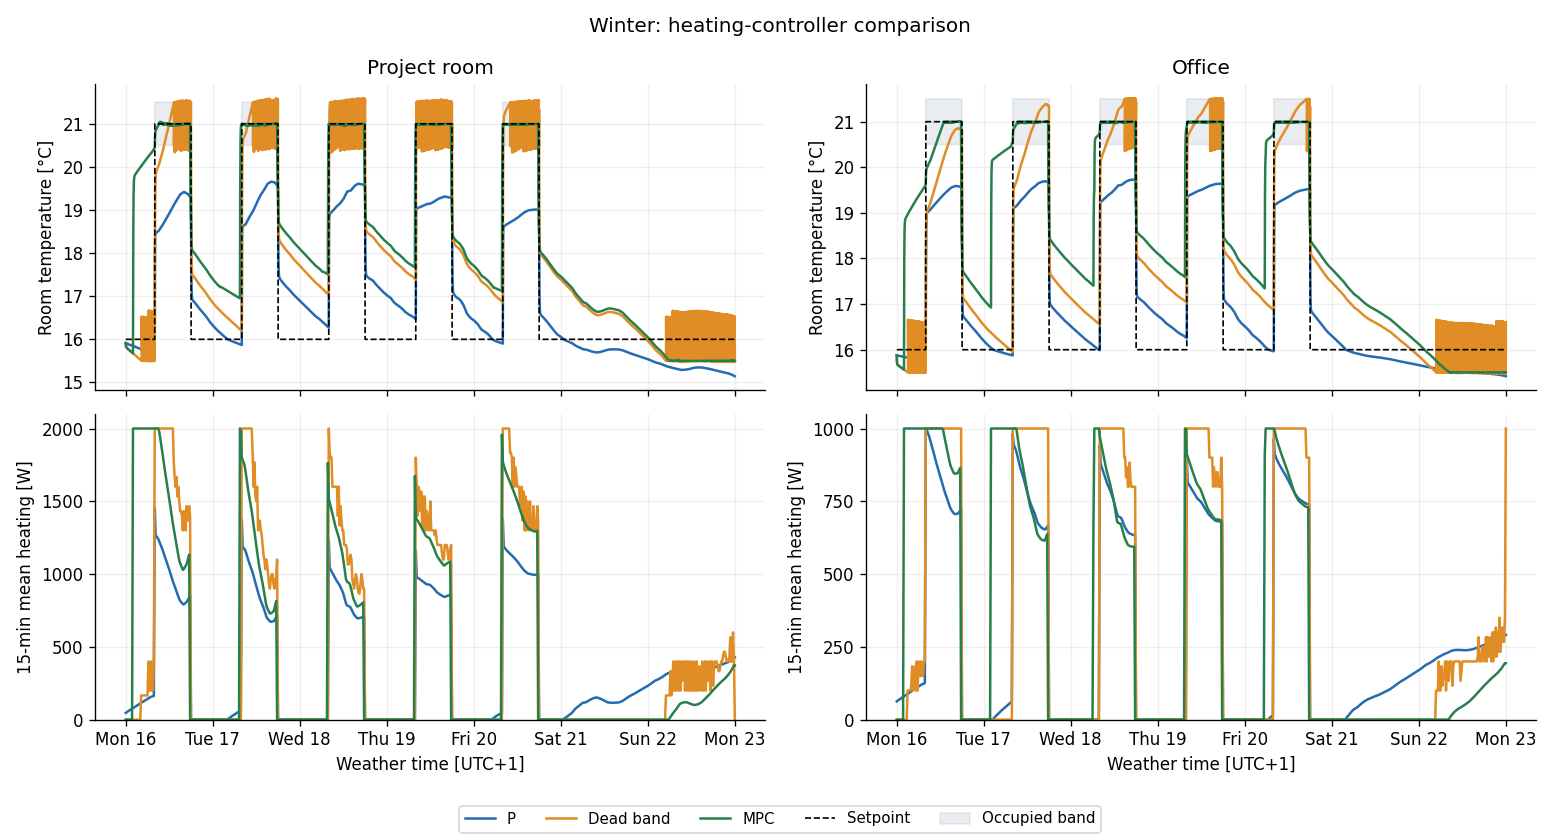

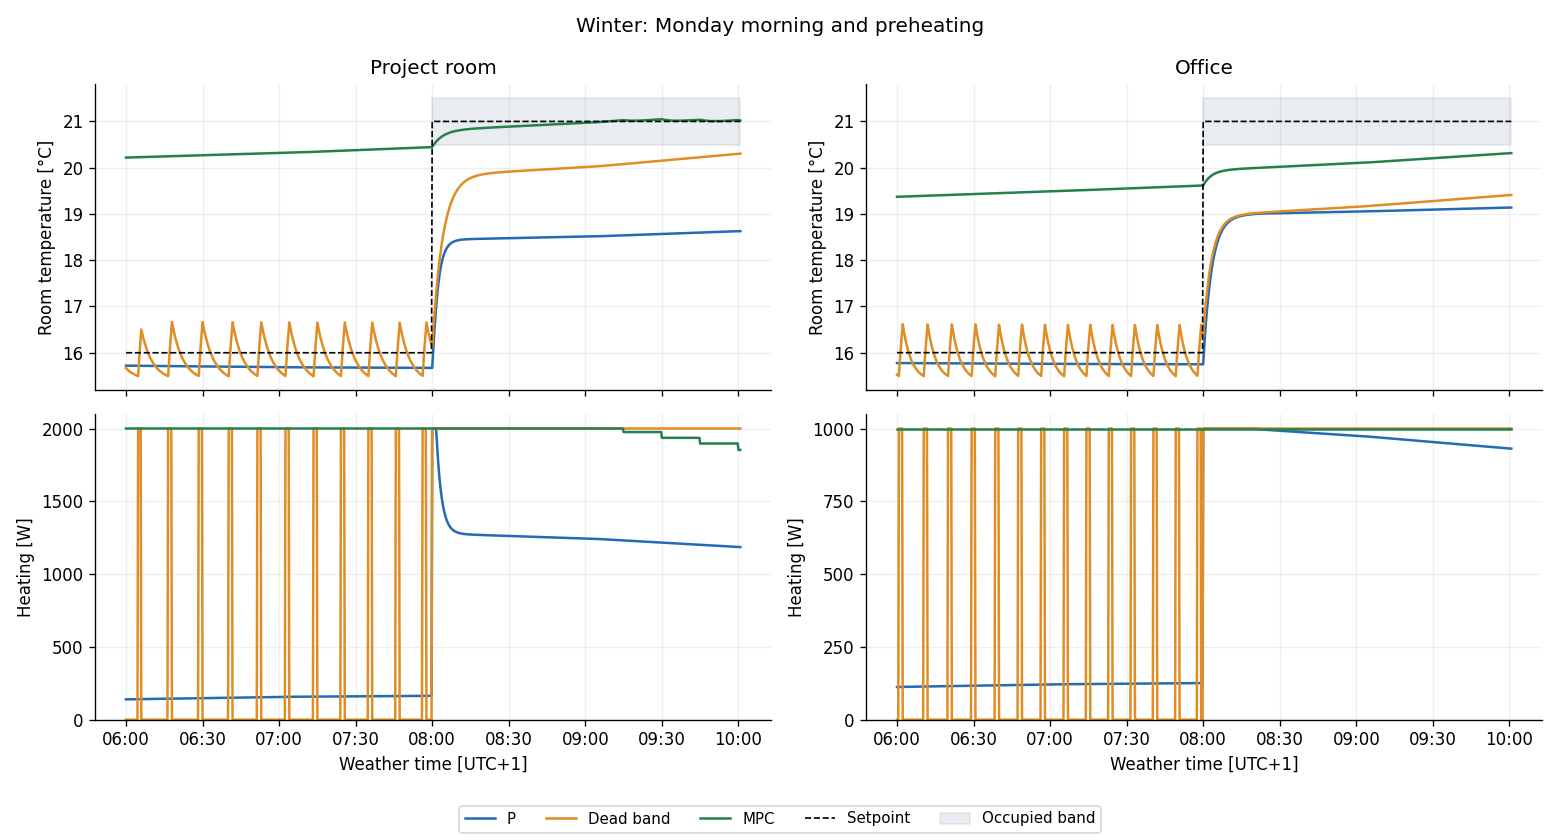

In [13]:
controller_colors = {"P": "#246bb2", "Dead band": "#df8d24", "MPC": "#27804c"}
for morning in [False, True]:
    fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex="col")
    for name, result in winter_results.items():
        shown = result.loc["2023-01-16 06:00":"2023-01-16 10:00"] if morning else result
        mean_power = shown if morning else shown.resample("15min").mean()
        for j, (temperature, power) in enumerate([
            ("Project [°C]", "Project heating [W]"), ("Office [°C]", "Office heating [W]")]):
            axes[0, j].plot(shown.index, shown[temperature], color=controller_colors[name], label=name)
            axes[1, j].plot(mean_power.index, mean_power[power], color=controller_colors[name])
    reference = shown
    occupied = reference["Occupied"].to_numpy()
    for j, label in enumerate(zone_labels):
        axes[0, j].plot(reference.index, reference["Setpoint [°C]"], color="black",
                        linestyle="--", linewidth=1, label="Setpoint")
        axes[0, j].fill_between(reference.index, np.where(occupied, 20.5, np.nan),
                                np.where(occupied, 21.5, np.nan), color="#94a3b8",
                                alpha=0.2, label="Occupied band")
        axes[0, j].set(title=label, ylabel="Room temperature [°C]")
        axes[1, j].set(ylabel="Heating [W]" if morning else "15-min mean heating [W]",
                        xlabel="Weather time [UTC+1]", ylim=(0, POWER_LIMIT[j] * 1.05))
        axes[1, j].set_yticks(np.linspace(0, POWER_LIMIT[j], 5))
        axes[1, j].ticklabel_format(axis="y", style="plain", useOffset=False)
        axes[1, j].xaxis.set_major_formatter(mdates.DateFormatter(
            "%H:%M" if morning else "%a %d", tz=hourly.index.tz))
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=5, fontsize=9)
    fig.suptitle("Winter: Monday morning and preheating" if morning else "Winter: heating-controller comparison")
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    plt.show()

The weekly heating-power curves use 15-minute averages so the thermostat's repeated switching remains readable. The morning plot shows the instantaneous commands. Proportional control responds to the current temperature error, the thermostat switches around its band, and MPC can heat before occupancy using the forecast. A finite P gain leaves a temperature error; comparisons must therefore include comfort as well as energy.

## 9. Summer window shading

Compare the existing windows with an assumed external blind that reduces transmitted window solar heat by 70%, represented by a factor of 0.3. Shading is deployed throughout the selected summer week, starting from the same initial state as the unshaded case. The wall and roof solar absorption, window U-values, occupancy and ventilation are unchanged. Both runs use the same capped P controller and have no cooling.

This is a simple solar-gain comparison.

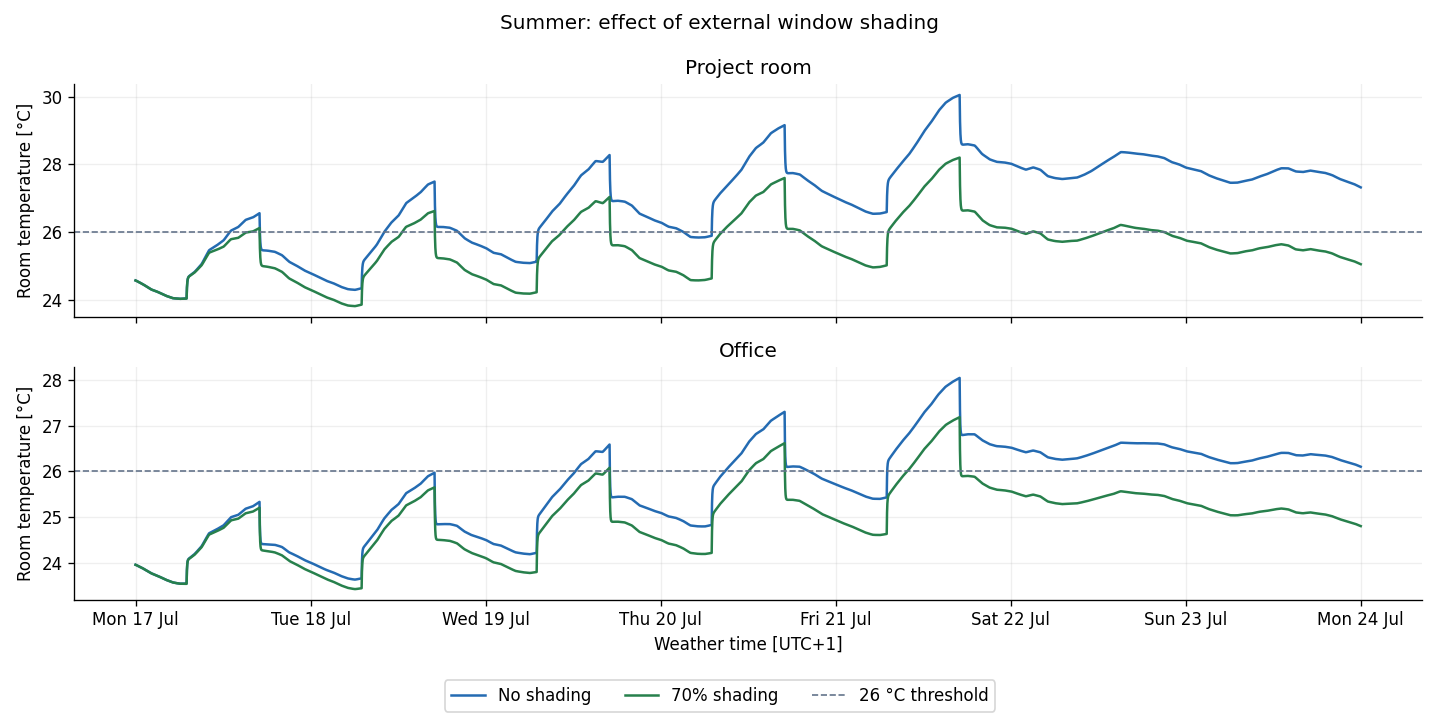

In [14]:
summer_results = {}
for name, factor in {"No shading": 1.0, "70% shading": 0.3}.items():
    result, _, _ = run_comparison(samples["Summer"], initial_states["Summer"],
                                 periods["Summer"][1], window_factor=factor)
    summer_results[name] = result

# Reducing a nonnegative solar input cannot make this unchanged thermal model warmer.
columns = ["Project [°C]", "Office [°C]"]
assert (summer_results["70% shading"][columns].to_numpy()
        <= summer_results["No shading"][columns].to_numpy() + 1e-8).all()
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for name, color in [("No shading", "#246bb2"), ("70% shading", "#27804c")]:
    result = summer_results[name]
    for j, column in enumerate(columns):
        axes[j].plot(result.index, result[column], color=color, label=name)
for ax, label in zip(axes, zone_labels):
    ax.axhline(26, color="#64748b", linestyle="--", linewidth=1, label="26 °C threshold")
    ax.set(title=label, ylabel="Room temperature [°C]")
axes[-1].set_xlabel("Weather time [UTC+1]")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b", tz=hourly.index.tz))
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3)
fig.suptitle("Summer: effect of external window shading")
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

## 10. Results and comparison

Heating energy is the heat delivered to the rooms, calculated as heating power times the 15 s step. Mean absolute error is the average absolute difference from 21 °C during occupied hours. Temperature-band and overheating hours are also counted only during occupancy. The final timestamp is an endpoint and is excluded from energy and duration sums.

The winter table also reports the change in heat stored in all nine capacity states. A positive value means more heat remains in the building at the end of the week. Different ending storage levels matter when interpreting a finite-week energy comparison.

In [15]:
winter_rows, winter_room_rows = [], []
for name, result in winter_results.items():
    intervals = result.iloc[:-1]
    occupied = intervals["Occupied"].to_numpy()
    assert np.isclose(occupied.sum() * DT / 3600, 50)
    temperatures = intervals[["Project [°C]", "Office [°C]"]].to_numpy()
    power = intervals[["Project heating [W]", "Office heating [W]"]].to_numpy()
    winter_rows.append({
        "Controller": name, "Heating [kWh]": power.sum() * DT / 3.6e6,
        "Occupied mean absolute error [K]": np.abs(temperatures[occupied] - 21).mean(),
        "Stored heat change [kWh]": winter_storage[name],
    })
    for j, label in enumerate(zone_labels):
        temperature = temperatures[occupied, j]
        winter_room_rows.append({
            "Controller": name, "Room": label,
            "Occupied mean [°C]": temperature.mean(),
            "Below 20.5 °C [h]": (temperature < 20.5).sum() * DT / 3600,
            "Above 21.5 °C [h]": (temperature > 21.5).sum() * DT / 3600,
        })
winter_summary = pd.DataFrame(winter_rows).set_index("Controller")
winter_rooms = pd.DataFrame(winter_room_rows).set_index(["Controller", "Room"])
display(winter_summary.round(2))
display(winter_rooms.round(2))

summer_rows = []
for name, result in summer_results.items():
    intervals = result.iloc[:-1]
    occupied = intervals["Occupied"].to_numpy()
    assert np.isclose(occupied.sum() * DT / 3600, 50)
    for j, (temperature, heating) in enumerate([
        ("Project [°C]", "Project heating [W]"), ("Office [°C]", "Office heating [W]")]):
        summer_rows.append({
            "Case": name, "Room": zone_labels[j],
            "Peak temperature [°C]": intervals[temperature].max(),
            "Occupied above 26 °C [h]": (intervals.loc[occupied, temperature] > 26).sum() * DT / 3600,
            "Heating [kWh]": intervals[heating].sum() * DT / 3.6e6,
        })
summer_summary = pd.DataFrame(summer_rows).set_index(["Case", "Room"])
display(summer_summary.round(2))
print("Power limits, MPC predictions, occupied hours and the shading comparison checked.")

,Heating [kWh],Occupied mean absolute error [K],Stored heat change [kWh]
Controller,,,
P,106.28,1.72,-23.15
Dead band,134.10,0.41,-11.13
MPC,136.70,0.08,-13.65


Occupied mean [°C]  ...  Above 21.5 °C [h]
Controller Room                              ...                   
P          Project room               19.12  ...               0.00
           Office                     19.44  ...               0.00
Dead band  Project room               20.97  ...               1.73
           Office                     20.74  ...               0.20
MPC        Project room               20.95  ...               0.00
           Office                     20.89  ...               0.00

[6 rows x 3 columns]

Peak temperature [°C]  ...  Heating [kWh]
Case        Room                                 ...               
No shading  Project room                  30.05  ...            0.0
            Office                        28.04  ...            0.0
70% shading Project room                  28.20  ...            0.0
            Office                        27.18  ...            0.0

[4 rows x 3 columns]

Power limits, MPC predictions, occupied hours and the shading comparison checked.


The tables above distinguish energy use from temperature comfort. The controller with the lowest heating demand is not automatically preferable if its rooms remain too cold.

In [16]:
p = winter_summary.loc["P"]
dead_band = winter_summary.loc["Dead band"]
mpc = winter_summary.loc["MPC"]
extra_mpc = 100 * (mpc["Heating [kWh]"] / dead_band["Heating [kWh]"] - 1)
project_before = summer_summary.loc[("No shading", "Project room")]
project_after = summer_summary.loc[("70% shading", "Project room")]
office_before = summer_summary.loc[("No shading", "Office")]
office_after = summer_summary.loc[("70% shading", "Office")]

display(Markdown(
    f"The proportional controller uses **{p['Heating [kWh]']:.1f} kWh**, but its occupied "
    f"mean absolute temperature error is **{p['Occupied mean absolute error [K]']:.2f} K**. "
    f"Dead-band control uses **{dead_band['Heating [kWh]']:.1f} kWh** with an error of "
    f"**{dead_band['Occupied mean absolute error [K]']:.2f} K**. MPC uses "
    f"**{mpc['Heating [kWh]']:.1f} kWh** and reduces the error to "
    f"**{mpc['Occupied mean absolute error [K]']:.2f} K**. Thus MPC provides the closest "
    f"tracking here, while using **{extra_mpc:.1f}% more heat than dead-band control**. "
    "This run demonstrates a comfort improvement, not a heating-energy saving.\n\n"
    "MPC preheats before 08:00, as the morning plot shows. It still cannot remove every "
    "morning temperature shortfall with the chosen power limits, prediction horizon and "
    "common initial state. The thermostat is simpler, but reacts only after its lower "
    "threshold is crossed and produces repeated temperature swings.\n\n"
    f"Shading lowers the summer peaks from **{project_before['Peak temperature [°C]']:.1f} "
    f"to {project_after['Peak temperature [°C]']:.1f} °C** in the project room and from "
    f"**{office_before['Peak temperature [°C]']:.1f} to {office_after['Peak temperature [°C]']:.1f} °C** "
    f"in the office. Occupied hours above 26 °C fall from "
    f"**{project_before['Occupied above 26 °C [h]']:.1f} to {project_after['Occupied above 26 °C [h]']:.1f} h** "
    f"and **{office_before['Occupied above 26 °C [h]']:.1f} to {office_after['Occupied above 26 °C [h]']:.1f} h**, "
    "respectively. Window shading helps, but internal and opaque-surface solar gains remain, "
    "so it does not eliminate summer overheating.\n\n"
    "For this project, shading is a useful simple summer improvement. Dead-band control "
    "is a simple way to improve winter temperatures, while MPC gives better tracking "
    "with greater implementation effort and stronger information assumptions."
))

The proportional controller uses **106.3 kWh**, but its occupied mean absolute temperature error is **1.72 K**. Dead-band control uses **134.1 kWh** with an error of **0.41 K**. MPC uses **136.7 kWh** and reduces the error to **0.08 K**. Thus MPC provides the closest tracking here, while using **1.9% more heat than dead-band control**. This run demonstrates a comfort improvement, not a heating-energy saving.

MPC preheats before 08:00, as the morning plot shows. It still cannot remove every morning temperature shortfall with the chosen power limits, prediction horizon and common initial state. The thermostat is simpler, but reacts only after its lower threshold is crossed and produces repeated temperature swings.

Shading lowers the summer peaks from **30.0 to 28.2 °C** in the project room and from **28.0 to 27.2 °C** in the office. Occupied hours above 26 °C fall from **40.8 to 30.9 h** and **22.8 to 12.6 h**, respectively. Window shading helps, but internal and opaque-surface solar gains remain, so it does not eliminate summer overheating.

For this project, shading is a useful simple summer improvement. Dead-band control is a simple way to improve winter temperatures, while MPC gives better tracking with greater implementation effort and stronger information assumptions.

## 11. Final conclusions and limits

Across the four notebooks, we defined a two-zone building, constructed and checked its thermal model, selected a stable and accurate simulation step, simulated weather and heat gains, and compared two focused improvements. Dead-band control improves winter comfort with simple control, MPC gives closer temperature tracking, and shading reduces summer overheating. These results depend on our simplified nine-state model and chosen building and usage assumptions.

**Sources:** Christian Ghiaus, [01WeatherData.ipynb](https://github.com/cghiaus/dm4bem/blob/2eb8803cf038bd73c1618f2fd89771b9ba285ab4/01WeatherData.ipynb), [03CubicBuilding.ipynb](https://github.com/cghiaus/dm4bem/blob/2eb8803cf038bd73c1618f2fd89771b9ba285ab4/03CubicBuilding.ipynb), [05SwitchModels.ipynb](https://github.com/cghiaus/dm4bem/blob/2eb8803cf038bd73c1618f2fd89771b9ba285ab4/05SwitchModels.ipynb) and [06Control_Input.ipynb](https://github.com/cghiaus/dm4bem/blob/2eb8803cf038bd73c1618f2fd89771b9ba285ab4/06Control_Input.ipynb).
